# Job 3 - Xử lý tín hiệu & AI học hành vi siết của chuyên gia

Notebook này làm phần việc của Job 3:

1. **Tiền xử lý & chuẩn hóa**: làm sạch tín hiệu, đưa mọi lần siết về cùng trục thời gian và trục góc, dùng **DTW (DBA)** để dựng **đường cong lực chuẩn** cùng dải dung sai.
2. **Mô hình hành vi chuyên gia**:
   - *Lực siết chuẩn*: với góc xoay và thời điểm hiện tại, lực chuẩn là bao nhiêu (kèm dải 5% - 95%).
   - *Điểm ngắt lực*: còn bao nhiêu độ nữa thì phải ngắt.
3. **Phân loại thao tác đúng/sai** (tối ưu accuracy): LightGBM + MiniRocket + InceptionTime, ghép ensemble.
4. **Mô phỏng robot siết** dùng mô hình điểm ngắt, so với luật dừng cố định.
5. **So sánh với dữ liệu nhóm tự thu từ găng tay** (Job 1 / Job 2), kèm thử nghiệm độ bền khi tín hiệu nhiễu và lấy mẫu thấp như găng tay.

**Dataset mở dùng để train: PyScrew** (West & Deuse, 2025 - arXiv:2505.11925, giấy phép CC-BY-4.0). Đây là dữ liệu siết vít công nghiệp với chuỗi thời gian **lực siết (Nm), góc xoay (độ), gradient (Nm/độ), thời gian**, lấy mẫu 833 Hz, lực mục tiêu 1.4 Nm. Mặc định dùng kịch bản **s04** (5.000 lần siết, 24 loại lỗi + thao tác chuẩn xen kẽ). Các kênh này khớp với găng tay của nhóm: cảm biến lực x cánh tay đòn → Nm, IMU → góc xoay.

**Cách chạy**
- Colab: Runtime → Change runtime type → GPU (T4), rồi Run all.
- Kaggle: bật *Internet* và *GPU* trong Settings, rồi Run all.
- Lần đầu chạy sẽ tải dữ liệu từ Zenodo (theo tác giả khoảng 2 GB cho s04), các lần sau dùng cache.
- Muốn kiểm tra code nhanh mà chưa tải dữ liệu: đặt `SMOKE_TEST = True` ở cell cấu hình (dùng dữ liệu giả lập, kết quả không có ý nghĩa).

In [1]:
# 0. Cài thư viện còn thiếu (Colab/Kaggle có sẵn numpy, pandas, sklearn, torch, lightgbm)
import importlib.util, subprocess, sys
need = {"pyscrew": "pyscrew", "lightgbm": "lightgbm", "tslearn": "tslearn", "aeon": "aeon", "joblib": "joblib"}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Đang cài:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("OK. Nếu pip báo đã đổi version numpy/pandas thì Runtime → Restart session rồi chạy lại từ cell này.")

Đang cài: ['pyscrew', 'tslearn', 'aeon']
OK. Nếu pip báo đã đổi version numpy/pandas thì Runtime → Restart session rồi chạy lại từ cell này.


In [2]:
# 1. Import & cấu hình
import os, sys, json, time, math, random, gc, warnings, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from sklearn.model_selection import train_test_split, KFold, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             mean_absolute_error, r2_score, log_loss, roc_auc_score)
import lightgbm as lgb
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

IN_KAGGLE = os.path.exists("/kaggle/working")
WORK_DIR = "/kaggle/working" if IN_KAGGLE else ("/content" if os.path.exists("/content") else os.getcwd())
CACHE_DIR = os.path.join(WORK_DIR, "pyscrew_cache")
OUT_DIR = os.path.join(WORK_DIR, "artifacts_job3")
os.makedirs(OUT_DIR, exist_ok=True)

SCENARIO = "s04"          # s04: 24 loại lỗi + chuẩn. Có thể thử s03, s05, s06
TASK = "multiclass"       # "multiclass": nhận ra loại lỗi cụ thể | "binary": chỉ đúng/sai
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # True: chạy thử bằng dữ liệu giả lập

SEED = 42
L_TIME = 512              # số điểm mỗi chuỗi sau khi resample theo thời gian
L_ANG = 256               # số điểm đường cong lực theo góc
ANGLE_WINDOW = 720        # xét 720 độ cuối trước điểm ngắt
L_ABS = 512               # số điểm khi resample theo góc tuyệt đối
ABS_ANGLE_MAX = 2200      # trục góc tuyệt đối 0 - 2200 độ (s04: phần lớn lần siết kết thúc ở 1700 - 2000 độ)
STOP_TOL = 3.0            # robot dừng khi mô hình báo còn <= 3 độ
GLOVE_FS = 100            # tần số lấy mẫu của găng tay (Hz) - sửa theo ESP32 của nhóm
GLOVE_TQ_NOISE = 0.03     # nhiễu loadcell sau khi quy ra Nm
GLOVE_ANG_NOISE = 1.0     # nhiễu góc của IMU (độ)
GLOVE_AUG_P = 0.5         # tỉ lệ mẫu train được thay bằng bản "kiểu găng tay" khi train CNN
CNN_EPOCHS = 3 if SMOKE_TEST else 60
CNN_SEEDS = [SEED] if SMOKE_TEST else [SEED, SEED + 1]   # nhiều seed → accuracy ổn định hơn
MR_KERNELS = 2000 if SMOKE_TEST else 10000
N_JOBS = os.cpu_count() or 2
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
_trapz = getattr(np, "trapezoid", None) or np.trapz
print("Device:", DEVICE, "| CPU:", N_JOBS, "| Output:", OUT_DIR, "| SMOKE_TEST:", SMOKE_TEST)

Device: cuda | CPU: 2 | Output: /content/artifacts_job3 | SMOKE_TEST: False


## 2. Tải dữ liệu

`pyscrew.get_data` tải và giải nén từ Zenodo. Mình tắt chuẩn hóa độ dài của thư viện (`target_length=0`) để giữ nguyên độ dài thật của từng lần siết, sau đó tự resample - như vậy không bị lẫn phần padding 0 vào tín hiệu.

Nhãn:
- `scenario_condition`: `normal` (thao tác chuẩn) / `faulty` (có lỗi được tạo có chủ đích). Trong s04, mỗi nhóm lỗi xen kẽ 5 lần chuẩn - 5 lần lỗi.
- Nhãn đa lớp = tên loại lỗi nếu `faulty`, ngược lại là `000_normal`.
- **`001_control-group` được gộp hết vào `000_normal`**: nhóm này không có can thiệp nào, nhưng file nhãn vẫn đánh `faulty` cho một nửa (theo lịch xen kẽ 5/5). Nửa đó giống hệt thao tác chuẩn nên không mô hình nào học được, giữ lại chỉ làm tụt accuracy.
- `workpiece_id` được lấy từ `labels.csv` (pyscrew trả về đúng thứ tự file này) để chia train/test **theo phôi**: 2 vít trái/phải của cùng một phôi luôn nằm chung một tập, tránh rò rỉ.
- Mô hình chuyên gia và đường chuẩn chỉ học từ lần siết `normal` **và** máy siết báo `OK` (có ~100 lần `normal` nhưng `NOK` - đó không phải thao tác mẫu).

In [3]:
def _strip_padding(t, *seqs):
    t = np.asarray(t, float)
    nz = np.nonzero(t > 0)[0]
    n = nz[-1] + 1 if len(nz) else len(t)
    return [np.asarray(s, float)[:n] for s in (t,) + seqs]

def load_pyscrew(scenario):
    import pyscrew
    kw = dict(scenario=scenario, cache_dir=CACHE_DIR, handle_duplicates="first", handle_missings="mean")
    try:
        d = pyscrew.get_data(target_length=0, **kw); padded = False
    except Exception as e:
        print("target_length=0 lỗi, chuyển sang pad 2000 điểm rồi tự cắt padding:", e)
        d = pyscrew.get_data(target_length=2000, **kw); padded = True
    runs = []
    for i in range(len(d["torque_values"])):
        seq = [d["time_values"][i], d["torque_values"][i], d["angle_values"][i],
               d["gradient_values"][i], d["step_values"][i]]
        if padded:
            seq = _strip_padding(*seq)
        t, tq, ang, gr, st = [np.asarray(s, float) for s in seq]
        runs.append(dict(time=t, torque=tq, angle=ang, gradient=np.nan_to_num(gr), step=st.astype(int)))
    keys = ["class_values", "workpiece_location", "workpiece_usage", "workpiece_result",
            "scenario_condition", "scenario_exception"]
    meta = pd.DataFrame({k: d[k] for k in keys if k in d})
    del d; gc.collect()
    meta["workpiece_id"] = _workpiece_ids(meta, scenario)
    return runs, meta

def _workpiece_ids(meta, scenario):
    # pyscrew đọc file theo đúng thứ tự labels.csv → ghép lại để lấy workpiece_id, có kiểm tra khớp từng dòng
    import glob
    sid = scenario if scenario.startswith("s0") else ""
    cands = [p for p in glob.glob(os.path.join(CACHE_DIR, "**", "labels.csv"), recursive=True) if sid[:3] in p]
    for path in cands:
        lab = pd.read_csv(path, dtype={"workpiece_id": str})
        if len(lab) == len(meta) and (lab["class_value"].astype(str).values == meta["class_values"].astype(str).values).all() \
                and (lab["workpiece_location"].astype(str).values == meta["workpiece_location"].astype(str).values).all():
            print("Đã ghép workpiece_id từ", path)
            return lab["workpiece_id"].values
    print("CẢNH BÁO: không ghép được workpiece_id → chia ngẫu nhiên theo từng lần siết")
    return np.arange(len(meta)).astype(str)

def make_synthetic(n_per_class=60, n_classes=6, seed=0):
    # Dữ liệu giả lập hình dạng giống đường cong siết vít, CHỈ để kiểm tra code chạy
    rng = np.random.default_rng(seed); runs, rows = [], []
    classes = ["001_control-group"] + [f"10{k}_fault-{k}" for k in range(1, n_classes)]
    for ci, c in enumerate(classes):
        for j in range(n_per_class):
            faulty = ci > 0 and (j % 10) >= 5
            n = int(rng.integers(900, 1400)); t = np.arange(n) / 833.33
            total = rng.normal(1400, 40) + (ci * 60 if faulty else 0)
            x = np.linspace(0, 1, n)
            ang = total * x + rng.normal(0, 0.25, n)
            fr = 0.35 * (1 + (0.15 * ci if faulty else 0))
            seat = 0.88 - (0.03 * ci if faulty else 0)
            peak = 1.4 + (0.1 * (ci % 3) if faulty else 0)
            tq = 0.05 + fr * np.clip(x / 0.15, 0, 1) + 0.1 * x
            tq = tq + np.where(x > seat, (peak - tq) * ((x - seat) / (1 - seat)) ** 2, 0)
            tq = tq + rng.normal(0, 0.01, n)
            gr = np.gradient(tq) / np.maximum(np.gradient(ang), 1e-3)
            st = np.digitize(x, [0.1, 0.6, seat])
            runs.append(dict(time=t, torque=tq, angle=ang, gradient=np.clip(gr, -1, 1), step=st))
            rows.append(dict(class_values=c, workpiece_location="left" if j % 2 else "right",
                             workpiece_id=f"{ci}_{j // 2}",
                             workpiece_usage=j % 25,
                             workpiece_result="NOK" if (faulty and rng.random() < 0.7) or rng.random() < 0.03 else "OK",
                             scenario_condition="faulty" if faulty else "normal", scenario_exception=0))
    return runs, pd.DataFrame(rows)

In [4]:
t0 = time.time()
raw_runs, meta = make_synthetic() if SMOKE_TEST else load_pyscrew(SCENARIO)
print(f"{len(raw_runs)} lần siết - tải trong {time.time() - t0:.0f}s")

# bỏ các lần siết bị đánh dấu có sự cố khi thí nghiệm
if "scenario_exception" in meta:
    keep = pd.to_numeric(meta["scenario_exception"], errors="coerce").fillna(0).values == 0
    raw_runs = [r for r, k in zip(raw_runs, keep) if k]
    meta = meta[keep].reset_index(drop=True)

cond = meta["scenario_condition"].astype(str).str.lower()
meta["is_faulty"] = cond.eq("faulty").astype(int)
if meta["is_faulty"].sum() == 0:      # kịch bản không có cột normal/faulty → dùng thẳng tên lớp
    print("Không có nhãn faulty, dùng class_values làm nhãn")
    meta["is_faulty"] = (~meta["class_values"].astype(str).str.contains("control|normal|000")).astype(int)
control = meta["class_values"].astype(str).str.contains("control", case=False)
print(f"Gộp {int((control & (meta['is_faulty'] == 1)).sum())} lần siết 'faulty' của nhóm control (không có can thiệp) vào thao tác chuẩn")
meta.loc[control, "is_faulty"] = 0
meta["target_multi"] = np.where(meta["is_faulty"] == 1, meta["class_values"], "000_normal")
res_ok = meta.get("workpiece_result", pd.Series(["OK"] * len(meta))).astype(str).str.upper().eq("OK").values
meta["is_expert"] = ((meta["is_faulty"] == 0).values & res_ok).astype(int)
print(f"Thao tác mẫu cho mô hình chuyên gia (normal + OK): {meta['is_expert'].sum()} / {(meta['is_faulty'] == 0).sum()} lần normal")
meta["target_name"] = (meta["target_multi"] if TASK == "multiclass"
                       else meta["is_faulty"].map({0: "OK", 1: "NOK"}))
le = LabelEncoder()
y = le.fit_transform(meta["target_name"])
N_CLASSES = len(le.classes_)
print("Số lớp:", N_CLASSES)
print(meta["target_name"].value_counts().to_string())

2026-10-02 10:53:15 - INFO - pyscrew.main - Starting data retrieval for scenario: s04 (assembly-conditions-2)
2026-10-02 10:53:15 - INFO - pyscrew.pipeline.loading - Using cache directory (absolute): /content/pyscrew_cache
2026-10-02 10:53:15 - INFO - pyscrew.pipeline.loading - Beginning data extraction for scenario 's04_variations-in-assembly-conditions-2.zip' (force=False)
2026-10-02 10:53:15 - INFO - pyscrew.pipeline.loading - Downloading dataset 's04_variations-in-assembly-conditions-2.zip' from Zenodo URL: https://zenodo.org/records/16031381/files/s04_variations-in-assembly-conditions-2.zip?download=1


2026-10-02 10:54:40 - INFO - pyscrew.pipeline.loading - Download of 's04_variations-in-assembly-conditions-2.zip' completed (61,107,763 bytes). Beginning checksum verification...
2026-10-02 10:54:40 - INFO - pyscrew.pipeline.loading - Verifying MD5 checksum for 's04_variations-in-assembly-conditions-2.zip'...
2026-10-02 10:54:40 - INFO - pyscrew.pipeline.loading - Checksum verification successful for 's04_variations-in-assembly-conditions-2.zip' (MD5: 7f580205863743c2b083cbeebfa61117)


2026-10-02 10:54:41 - INFO - pyscrew.pipeline.loading - Extracting archive 's04_variations-in-assembly-conditions-2.zip' to directory: /content/pyscrew_cache/extracted/s04_variations-in-assembly-conditions-2
2026-10-02 10:54:43 - INFO - pyscrew.pipeline.loading - Extraction of 's04_variations-in-assembly-conditions-2.zip' completed successfully to: /content/pyscrew_cache/extracted/s04_variations-in-assembly-conditions-2
2026-10-02 10:54:43 - INFO - pyscrew.core.dataset - Selected 5000 files
2026-10-02 10:54:52 - INFO - pyscrew.core.dataset - Successfully loaded 5000 screw runs
2026-10-02 10:54:52 - INFO - pyscrew.pipeline.processing - Adding input_logging transformer to pipeline
2026-10-02 10:54:52 - INFO - pyscrew.pipeline.processing - Adding step_unpacking transformer to pipeline
2026-10-02 10:54:52 - INFO - pyscrew.pipeline.processing - Adding duplicate handling with first
2026-10-02 10:54:52 - INFO - pyscrew.pipeline.processing - Adding handling of missings with mean
2026-10-02 10:

2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.handle_missings - Completed missing interpolation using 'mean' method (interval=0.0012)
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.handle_missings - Processed 5,000 series with 7,182,172 total points
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.handle_missings - Found gaps - min: 0.0012s, max: 0.1116s, avg: 0.0012s
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.handle_missings - Added 255,241 points (+3.55% of total)
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.handle_missings - Average 51.0 points added per series


2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.convert_dataset - Output format is 'list' - keeping the default format
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - Output - Fit: Dataset contains 5000 runs
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - time_values: 5000 runs
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - torque_values: 5000 runs
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - angle_values: 5000 runs
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - gradient_values: 5000 runs
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - step_values: 5000 runs
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - class_values: 5000 values
2026-10-02 10:58:06 - INFO - pyscrew.pipeline.transformers.pipeline_logging - workpiece_location: 5000 values
2026-10-02 10:58:06 - INF

## 3. Tiền xử lý

Với mỗi lần siết:
- Sửa trục thời gian nếu bị lặp/lùi, đưa về bắt đầu từ 0.
- **Góc tích lũy**: góc có thể reset khi chuyển bước của chương trình siết, nên cộng dồn phần tăng để được một trục góc đơn điệu.
- Làm mượt lực bằng Savitzky-Golay (cửa sổ ~13 ms, tự co giãn theo tần số lấy mẫu). Với dữ liệu găng tay có thêm **Kalman** ở mục 9.
- **Điểm ngắt lực**: thời điểm đầu tiên lực đạt 98% lực đỉnh.
- Tạo 2 biểu diễn:
  - `X_time` (N, 4, 512): lực, góc, gradient dT/dθ (tự tính từ lực và góc), vận tốc góc theo thời gian chuẩn hóa → cho CNN / MiniRocket. Cả 4 kênh đều tính được từ găng tay nên mô hình dùng lại được cho dữ liệu nhóm.
  - `X_ang` (N, 256): lực theo góc, căn thẳng tại điểm ngắt, xét 720 độ cuối → cho DTW và đường cong chuẩn.
  - `X_abs` (N, 3, 512): lực, gradient, thời gian theo **góc tuyệt đối** 0 - 2200 độ → cho CNN thứ hai. Biểu diễn này giữ nguyên mức ma sát ở từng vòng ren, thứ mà `X_time` bị co giãn mất (quan trọng với các lỗi như vít phủ khác, bề mặt ẩm, ren biến dạng).

In [5]:
ANG_GRID = np.linspace(-ANGLE_WINDOW, 0, L_ANG)
ABS_GRID = np.linspace(0, ABS_ANGLE_MAX, L_ABS)

def _odd(n): n = int(n); return n if n % 2 else n + 1

def derive_gradient(tq, ang, t, win_s=0.02):
    # dùng khi nguồn dữ liệu (găng tay) không có sẵn gradient: dT/dθ trên cửa sổ ~20 ms
    dt = np.median(np.diff(t)) if len(t) > 1 else 1 / 833.33
    w = max(1, int(round(win_s / max(dt, 1e-6))))
    i = np.arange(len(tq)); j = np.maximum(i - w, 0)
    return (tq - tq[j]) / np.maximum(ang - ang[j], 0.5)

def clean_run(r):
    t = np.asarray(r["time"], float); tq = np.nan_to_num(np.asarray(r["torque"], float))
    ang = np.nan_to_num(np.asarray(r["angle"], float)); n = len(tq)
    dt = np.diff(t)
    if n > 1 and (dt <= 0).any():                                    # thời gian lặp / reset giữa các bước
        base = np.median(dt[dt > 0]) if (dt > 0).any() else 1 / 833.33
        t = np.r_[0.0, np.cumsum(np.where(dt > 0, dt, base))]
    t = t - t[0]
    da = np.diff(ang, prepend=ang[0]); da[da < -5] = 0.0          # góc reset giữa các bước
    a = np.maximum.accumulate(np.cumsum(da)); a = a - a[0]
    fs = 1.0 / max(np.median(np.diff(t)) if n > 1 else 1 / 833.33, 1e-6)
    win = min(_odd(max(5, 0.013 * fs)), _odd(n) - 2 if n >= 7 else 0)
    tq_s = savgol_filter(tq, win, 2) if win >= 5 else tq.copy()
    g_der = derive_gradient(tq_s, a, t)            # gradient tự tính: găng tay cũng tính được y hệt
    g = r.get("gradient")
    g = g_der if g is None else np.nan_to_num(np.asarray(g, float))   # gradient của máy siết (chỉ dùng cho LightGBM)
    vel = np.gradient(a) / np.maximum(np.gradient(t), 1e-6) if n > 2 else np.zeros(n)
    st = np.asarray(r.get("step", np.zeros(n)), int)
    cut = int(np.argmax(tq_s >= 0.98 * tq_s.max()))
    return dict(t=t, torque=tq, torque_s=tq_s, angle=a, gradient=g, grad_der=g_der, vel=vel, step=st, cut=cut, fs=fs)

def resample_time(c, L=L_TIME):
    # 4 kênh đều tính được từ găng tay (lực + góc) → mô hình chuỗi thời gian chuyển sang găng tay được
    src = np.linspace(0, 1, len(c["t"])); dst = np.linspace(0, 1, L)
    return np.stack([np.interp(dst, src, c[k]) for k in ("torque", "angle", "grad_der", "vel")]).astype(np.float32)

def resample_angle(c):
    k = c["cut"]; a = c["angle"][:k + 1] - c["angle"][k]; y_ = c["torque_s"][:k + 1]
    a_u, idx = np.unique(a, return_index=True)
    if len(a_u) < 2:
        return np.full(L_ANG, y_[-1], np.float32)
    return np.interp(ANG_GRID, a_u, y_[idx], left=y_[idx][0]).astype(np.float32)

def resample_absangle(c):
    a_u, idx = np.unique(c["angle"], return_index=True)
    if len(a_u) < 2:
        return np.zeros((3, L_ABS), np.float32)
    tq = np.interp(ABS_GRID, a_u, c["torque_s"][idx], right=0.0)      # sau khi dừng: lực = 0
    gr = np.interp(ABS_GRID, a_u, c["grad_der"][idx], right=0.0)
    tm = np.interp(ABS_GRID, a_u, c["t"][idx], right=c["t"][-1])      # thời gian để đạt từng góc
    return np.stack([tq, np.clip(gr, -0.05, 0.05), tm]).astype(np.float32)

def prepare(runs, desc="Tiền xử lý"):
    C = [clean_run(r) for r in tqdm(runs, desc=desc)]
    Xt = np.stack([resample_time(c) for c in C])
    Xa = np.stack([resample_angle(c) for c in C])
    Xb = np.stack([resample_absangle(c) for c in C])
    return C, Xt, Xa, Xb

C, X_time, X_ang, X_abs = prepare(raw_runs)
print("X_time:", X_time.shape, "| X_ang:", X_ang.shape, "| X_abs:", X_abs.shape)
print("Tần số lấy mẫu trung vị: %.0f Hz | số điểm trung vị: %d" %
      (np.median([c["fs"] for c in C]), np.median([len(c["t"]) for c in C])))

Tiền xử lý:   0%|          | 0/4965 [00:00<?, ?it/s]

X_time: (4965, 4, 512) | X_ang: (4965, 256) | X_abs: (4965, 3, 512)
Tần số lấy mẫu trung vị: 833 Hz | số điểm trung vị: 1460


In [6]:
# Chia train / val / test ≈ 70 / 15 / 15 theo phôi (StratifiedGroupKFold), giữ tỉ lệ lớp
idx_all = np.arange(len(y))
groups = meta["workpiece_id"].astype(str).values
def group_split(idx, n_splits, seed):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    a, b = next(sgkf.split(idx, y[idx], groups[idx]))
    return idx[a], idx[b]
idx_trva, idx_te = group_split(idx_all, 7, SEED)          # ~14% test
idx_tr, idx_va = group_split(idx_trva, 6, SEED + 1)       # ~14% val
assert not (set(groups[idx_tr]) & set(groups[idx_te])) and not (set(groups[idx_va]) & set(groups[idx_te]))
is_faulty = meta["is_faulty"].values
is_expert = meta["is_expert"].values
normal_tr = idx_tr[is_faulty[idx_tr] == 0]
expert_tr, expert_va, expert_te = (ix[is_expert[ix] == 1] for ix in (idx_tr, idx_va, idx_te))
print(f"train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)} | thao tác mẫu (normal+OK) trong train: {len(expert_tr)}")
print("Số lớp có mặt trong test:", len(np.unique(y[idx_te])), "/", N_CLASSES)

train 3545 | val 712 | test 708 | thao tác mẫu (normal+OK) trong train: 1745
Số lớp có mặt trong test: 25 / 25


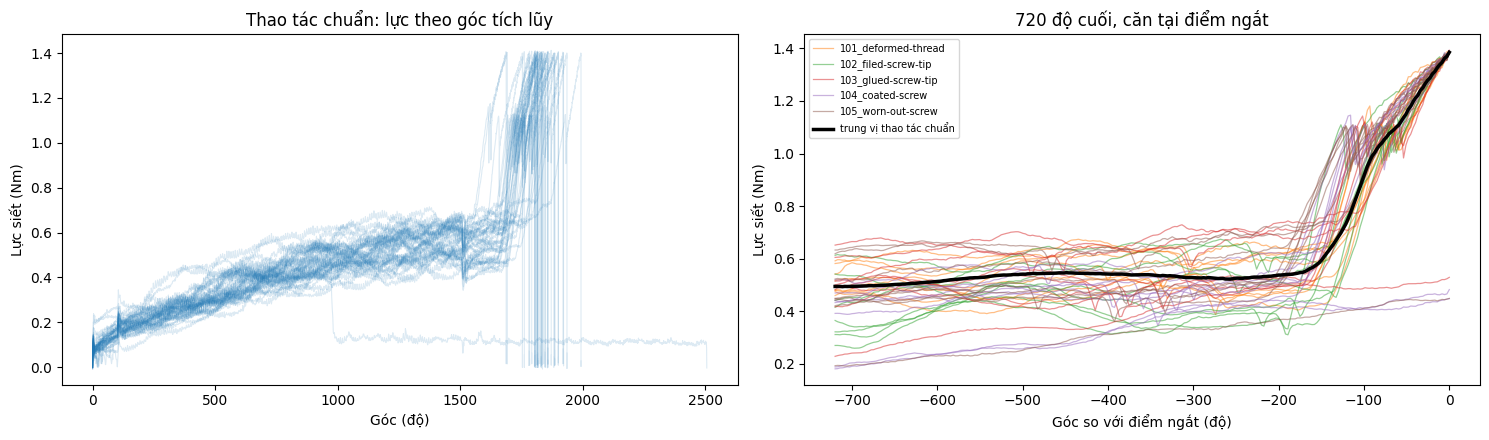

In [7]:
# EDA: đường cong lực - góc của thao tác chuẩn và vài loại lỗi
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for i in rng.choice(normal_tr, min(40, len(normal_tr)), replace=False):
    axes[0].plot(C[i]["angle"], C[i]["torque"], color="tab:blue", alpha=0.15, lw=0.8)
axes[0].set(title="Thao tác chuẩn: lực theo góc tích lũy", xlabel="Góc (độ)", ylabel="Lực siết (Nm)")
fault_names = [n for n in pd.unique(meta["target_multi"]) if n != "000_normal"][:5]
for n_, col in zip(fault_names, plt.cm.tab10.colors[1:]):
    ids = np.where(meta["target_multi"].values == n_)[0][:8]
    for k, i in enumerate(ids):
        axes[1].plot(ANG_GRID, X_ang[i], color=col, alpha=0.5, lw=0.9, label=n_ if k == 0 else None)
axes[1].plot(ANG_GRID, np.median(X_ang[normal_tr], 0), "k", lw=2.5, label="trung vị thao tác chuẩn")
axes[1].set(title=f"{ANGLE_WINDOW} độ cuối, căn tại điểm ngắt", xlabel="Góc so với điểm ngắt (độ)", ylabel="Lực siết (Nm)")
axes[1].legend(fontsize=7); plt.tight_layout(); plt.show()

## 4. Đường cong lực chuẩn bằng DTW

- **Đường chuẩn theo DTW**: căn từng lần siết chuẩn về một đường tham chiếu bằng DTW rồi lấy trung vị từng điểm, lặp 3 lần. Nhờ căn trước nên đường chuẩn không bị "nhòe" như trung bình thường, nhờ dùng trung vị nên không bị gai như DBA hay soft-DTW.
- **Dải dung sai**: phân vị 5% - 95% của thao tác chuẩn trên từng điểm góc.
- Với mỗi lần siết, tính khoảng cách DTW tới đường chuẩn và tỉ lệ điểm nằm ngoài dải → vừa dùng để cảnh báo trên dashboard (Job 2), vừa làm feature cho mô hình phân loại.

Đường chuẩn (trung vị sau căn DTW) xong sau 8.0s


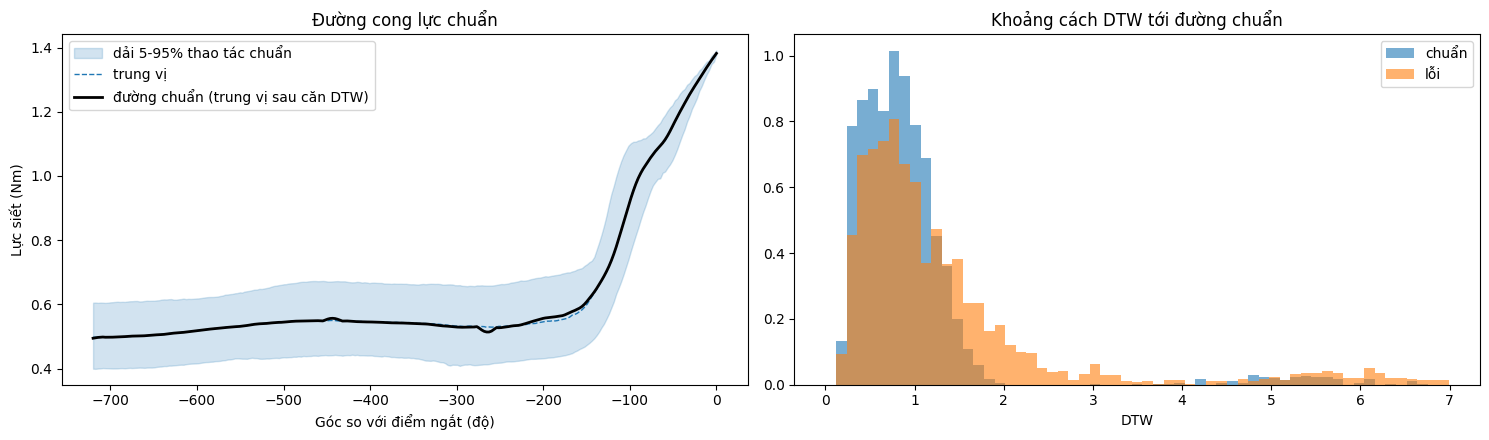

AUC tách chuẩn/lỗi chỉ bằng khoảng cách DTW: 0.619


In [8]:
from tslearn.metrics import cdist_dtw, dtw_path

R_DTW = int(0.1 * L_ANG)
sub = rng.choice(expert_tr, min(300, len(expert_tr)), replace=False)
band_lo, band_med, band_hi = np.percentile(X_ang[expert_tr], [5, 50, 95], axis=0)
t0 = time.time()
# Trung vị sau khi căn bằng DTW: căn từng đường về đường tham chiếu rồi lấy trung vị từng điểm, lặp 3 lần.
# Trung vị của 300 đường không bị kéo bởi vài đường lệch nên không sinh gai như DBA / soft-DTW.
def dtw_aligned_median(X, ref, radius, n_iter=3):
    for _ in range(n_iter):
        M = np.empty_like(X)
        for k, x in enumerate(X):
            path, _ = dtw_path(ref, x, global_constraint="sakoe_chiba", sakoe_chiba_radius=radius)
            pth = np.asarray(path)
            ssum = np.bincount(pth[:, 0], weights=x[pth[:, 1]], minlength=len(ref))
            M[k] = ssum / np.maximum(np.bincount(pth[:, 0], minlength=len(ref)), 1)
        ref = np.median(M, 0)
    return ref
std_curve = savgol_filter(dtw_aligned_median(X_ang[sub].astype(float), band_med.astype(float), R_DTW), 9, 2)
curve_method = "trung vị sau căn DTW"
print(f"Đường chuẩn ({curve_method}) xong sau {time.time() - t0:.1f}s")

D_dtw = cdist_dtw(X_ang[:, :, None], std_curve[None, :, None], global_constraint="sakoe_chiba",
                  sakoe_chiba_radius=R_DTW, n_jobs=-1).ravel()
curve_feats = pd.DataFrame({
    "dtw_to_std": D_dtw,
    "l2_to_median": np.sqrt(((X_ang - band_med) ** 2).mean(1)),
    "maxdev_median": np.abs(X_ang - band_med).max(1),
    "frac_out_band": ((X_ang < band_lo) | (X_ang > band_hi)).mean(1),
})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].fill_between(ANG_GRID, band_lo, band_hi, color="tab:blue", alpha=0.2, label="dải 5-95% thao tác chuẩn")
axes[0].plot(ANG_GRID, band_med, "tab:blue", lw=1, ls="--", label="trung vị")
axes[0].plot(ANG_GRID, std_curve, "k", lw=2, label=f"đường chuẩn ({curve_method})")
axes[0].set(title="Đường cong lực chuẩn", xlabel="Góc so với điểm ngắt (độ)", ylabel="Lực siết (Nm)"); axes[0].legend()
bins_ = np.linspace(0, np.percentile(D_dtw, 99), 60)
axes[1].hist(D_dtw[is_faulty == 0], bins=bins_, alpha=0.6, density=True, label="chuẩn")
axes[1].hist(D_dtw[is_faulty == 1], bins=bins_, alpha=0.6, density=True, label="lỗi")
axes[1].set(title="Khoảng cách DTW tới đường chuẩn", xlabel="DTW"); axes[1].legend()
plt.tight_layout(); plt.show()
print("AUC tách chuẩn/lỗi chỉ bằng khoảng cách DTW: %.3f" % roc_auc_score(is_faulty, D_dtw))

## 5. Mô hình hành vi chuyên gia

Chỉ học trên các lần siết **chuẩn và được máy siết báo OK** (đóng vai chuyên gia). Đầu vào chỉ gồm những gì găng tay đo được theo thời gian thực (góc, thời gian, vận tốc góc, lực hiện tại...), không dùng thông tin bước của máy siết để mô hình chuyển được sang găng tay.

**5a. Lực siết chuẩn** - LightGBM hồi quy phân vị: `f(góc, thời điểm, vận tốc góc)` → lực chuẩn (trung vị) và dải 5% - 95%.

**5b. Điểm ngắt lực** - LightGBM dự đoán *số độ còn lại tới điểm ngắt* từ trạng thái hiện tại. Robot/người siết dừng khi giá trị này về 0.

[5a] Lực chuẩn trên test (thao tác mẫu): MAE = 0.0467 Nm | R2 = 0.9691 | tỉ lệ nằm trong dải 5-95% = 89.9% (36s)


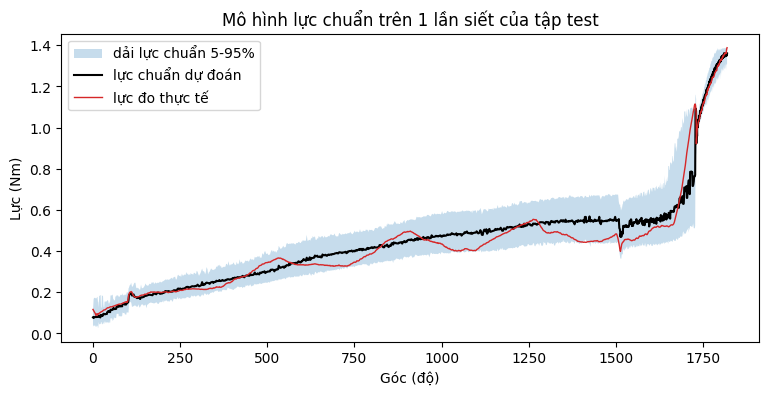

In [9]:
EXPERT_FEATS = ["angle", "t", "vel"]
CUT_FEATS = ["angle", "t", "vel", "torque", "slope_s", "slope_l", "tq_mean_s", "tq_max_sofar"]

def point_table(c, idx=None, n_pts=None, dense_end=0):
    k = c["cut"]
    if idx is None:
        if n_pts is None:
            idx = np.arange(k + 1)
        else:
            idx = np.linspace(0, k, min(n_pts, k + 1)).astype(int)
            if dense_end:
                idx = np.r_[idx, np.linspace(int(0.85 * k), k, dense_end).astype(int)]
            idx = np.unique(idx)
    a, tq, t = c["angle"], c["torque_s"], c["t"]
    dt = np.median(np.diff(t)) if len(t) > 1 else 1 / 833.33
    ws, wl = max(1, int(round(0.02 / dt))), max(2, int(round(0.08 / dt)))
    js, jl = np.maximum(idx - ws, 0), np.maximum(idx - wl, 0)
    return pd.DataFrame({
        "angle": a[idx], "t": t[idx], "vel": c["vel"][idx], "torque": tq[idx],
        "slope_s": (tq[idx] - tq[js]) / np.maximum(a[idx] - a[js], 0.25),
        "slope_l": (tq[idx] - tq[jl]) / np.maximum(a[idx] - a[jl], 0.25),
        "tq_mean_s": pd.Series(tq).rolling(ws + 1, min_periods=1).mean().values[idx],
        "tq_max_sofar": np.maximum.accumulate(tq)[idx],
        "pos": idx / max(k, 1),
        "remaining": a[k] - a[idx],
    })

def build_points(ids, n_pts=100, dense_end=0):
    return pd.concat([point_table(C[i], n_pts=n_pts, dense_end=dense_end).assign(run=i) for i in ids],
                     ignore_index=True)

def fit_quantiles(P, n_estimators=500):
    models = {}
    for q in (0.05, 0.5, 0.95):
        m = lgb.LGBMRegressor(objective="quantile", alpha=q, n_estimators=n_estimators, learning_rate=0.05,
                              num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1,
                              verbose=-1, random_state=SEED, n_jobs=N_JOBS)
        models[q] = m.fit(P[EXPERT_FEATS], P["torque"])
    return models

# ---- 5a. Lực siết chuẩn ----
t0 = time.time()
P_tr = build_points(expert_tr, 100)
expert = fit_quantiles(P_tr)
P_te = build_points(expert_te, 100)
q = {k: m.predict(P_te[EXPERT_FEATS]) for k, m in expert.items()}
lo, med, hi = np.minimum(q[0.05], q[0.5]), q[0.5], np.maximum(q[0.95], q[0.5])
expert_metrics = {
    "MAE_Nm": float(mean_absolute_error(P_te["torque"], med)),
    "R2": float(r2_score(P_te["torque"], med)),
    "coverage_5_95": float(((P_te["torque"] >= lo) & (P_te["torque"] <= hi)).mean()),
}
print(f"[5a] Lực chuẩn trên test (thao tác mẫu): MAE = {expert_metrics['MAE_Nm']:.4f} Nm | "
      f"R2 = {expert_metrics['R2']:.4f} | tỉ lệ nằm trong dải 5-95% = {expert_metrics['coverage_5_95']:.1%} "
      f"({time.time() - t0:.0f}s)")

i0 = expert_te[0]; Pi = point_table(C[i0])
plt.figure(figsize=(9, 4))
plt.fill_between(Pi["angle"], expert[0.05].predict(Pi[EXPERT_FEATS]), expert[0.95].predict(Pi[EXPERT_FEATS]),
                 alpha=0.25, label="dải lực chuẩn 5-95%")
plt.plot(Pi["angle"], expert[0.5].predict(Pi[EXPERT_FEATS]), "k", label="lực chuẩn dự đoán")
plt.plot(Pi["angle"], Pi["torque"], "tab:red", lw=1, label="lực đo thực tế")
plt.xlabel("Góc (độ)"); plt.ylabel("Lực (Nm)"); plt.title("Mô hình lực chuẩn trên 1 lần siết của tập test")
plt.legend(); plt.show()

In [10]:
# Feature "độ lệch so với chuyên gia" cho mô hình phân loại.
# Với các lần siết chuẩn trong train dùng out-of-fold để tránh rò rỉ nhãn.
def residual_feats(models, ids):
    P = build_points(ids, 100)
    q05, q50, q95 = (models[k].predict(P[EXPERT_FEATS]) for k in (0.05, 0.5, 0.95))
    P["res"] = P["torque"] - q50
    P["absres"] = P["res"].abs()
    P["out"] = ((P["torque"] < np.minimum(q05, q50)) | (P["torque"] > np.maximum(q95, q50))).astype(float)
    P["res_end"] = np.where(P["pos"] >= 0.8, P["res"], np.nan)
    g = P.groupby("run")
    return pd.DataFrame({"exp_res_mean": g["res"].mean(), "exp_res_abs": g["absres"].mean(),
                         "exp_res_max": g["absres"].max(), "exp_res_end": g["res_end"].mean(),
                         "exp_frac_out": g["out"].mean()})

t0 = time.time()
parts = []
for f_in, f_out in KFold(3, shuffle=True, random_state=SEED).split(expert_tr):
    m_fold = fit_quantiles(build_points(expert_tr[f_in], 100), n_estimators=300)
    parts.append(residual_feats(m_fold, expert_tr[f_out]))
others = np.setdiff1d(idx_all, expert_tr)
parts.append(residual_feats(expert, others))
expert_feats = pd.concat(parts).sort_index().reindex(idx_all)
print(f"Feature lệch chuẩn xong ({time.time() - t0:.0f}s)")

Feature lệch chuẩn xong (71s)


[5b] Điểm ngắt trên test: MAE toàn bộ = 18.2 độ | MAE trong 180 độ cuối = 4.6 độ (trung vị 2.4) | R2 = 0.9971 (76s)


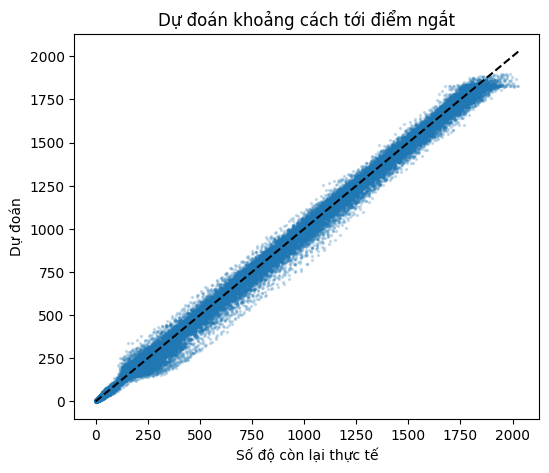

In [11]:
# ---- 5b. Điểm ngắt lực: dự đoán số độ còn lại ----
t0 = time.time()
Pc_tr = build_points(expert_tr, 120, dense_end=60)
Pc_va = build_points(expert_va, 120, dense_end=60)
cut_model = lgb.LGBMRegressor(objective="l1", n_estimators=3000, learning_rate=0.03, num_leaves=63,
                              min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              verbose=-1, random_state=SEED, n_jobs=N_JOBS)
cut_model.fit(Pc_tr[CUT_FEATS], Pc_tr["remaining"], eval_set=[(Pc_va[CUT_FEATS], Pc_va["remaining"])],
              callbacks=[lgb.early_stopping(200, verbose=False)])
Pc_te = build_points(expert_te, 120, dense_end=60)
pred_rem = cut_model.predict(Pc_te[CUT_FEATS])
near = Pc_te["remaining"].values <= 180
cut_metrics = {
    "MAE_deg_all": float(mean_absolute_error(Pc_te["remaining"], pred_rem)),
    "median_AE_deg_last180": float(np.median(np.abs(Pc_te["remaining"][near] - pred_rem[near]))),
    "MAE_deg_last180": float(mean_absolute_error(Pc_te["remaining"][near], pred_rem[near])),
    "R2": float(r2_score(Pc_te["remaining"], pred_rem)),
}
print(f"[5b] Điểm ngắt trên test: MAE toàn bộ = {cut_metrics['MAE_deg_all']:.1f} độ | "
      f"MAE trong 180 độ cuối = {cut_metrics['MAE_deg_last180']:.1f} độ (trung vị {cut_metrics['median_AE_deg_last180']:.1f}) | R2 = {cut_metrics['R2']:.4f} "
      f"({time.time() - t0:.0f}s)")
plt.figure(figsize=(6, 5))
plt.scatter(Pc_te["remaining"], pred_rem, s=2, alpha=0.2)
mx = Pc_te["remaining"].max(); plt.plot([0, mx], [0, mx], "k--")
plt.xlabel("Số độ còn lại thực tế"); plt.ylabel("Dự đoán"); plt.title("Dự đoán khoảng cách tới điểm ngắt"); plt.show()

## 6. Phân loại thao tác đúng/sai - tối ưu accuracy

Ba mô hình bổ sung cho nhau, sau đó ghép ensemble với trọng số chọn trên tập val:

| Mô hình | Đầu vào | Điểm mạnh |
|---|---|---|
| LightGBM | ~150 feature vật lý: thời lượng, góc tổng, lực đỉnh, độ dốc cuối, năng lượng siết, thống kê theo từng bước, độ lệch so với đường chuẩn và mô hình chuyên gia | dễ giải thích cho báo cáo (feature importance) |
| MiniRocket + Ridge | `X_time` 4 kênh | rất mạnh với chuỗi thời gian, train nhanh |
| InceptionTime - miền thời gian | `X_time` 4 kênh | học được hình dạng cục bộ của đường cong |
| InceptionTime - miền góc | `X_abs` 3 kênh | thấy được lực ở từng vòng ren, bổ sung cho mô hình trên |

Sau khi ghép, hiệu chỉnh thêm một hệ số cho lớp `000_normal` trên tập val (mô hình hay nghiêng về "chuẩn" vì lớp này đông nhất). Báo cáo cả accuracy lẫn macro-F1 (vì lớp `000_normal` đông hơn nhiều so với từng loại lỗi).

In [12]:
def run_features(c, xa, xt, xb):
    t, tq, tqs, a, g, v, st, k = c["t"], c["torque"], c["torque_s"], c["angle"], c["gradient"], c["vel"], c["step"], c["cut"]
    f = {"duration": t[-1], "n_points": len(t), "total_angle": a[-1], "cut_angle": a[k], "cut_time": t[k],
         "peak_torque": tqs[k], "final_torque": tq[-1], "post_cut_angle": a[-1] - a[k],
         "post_cut_time": t[-1] - t[k], "mean_speed": a[k] / max(t[k], 1e-6)}
    for name, x in (("tq", tq), ("gr", g), ("vel", v)):
        f[f"{name}_mean"], f[f"{name}_std"], f[f"{name}_max"], f[f"{name}_min"] = x.mean(), x.std(), x.max(), x.min()
        for p_ in (5, 25, 50, 75, 95):
            f[f"{name}_p{p_}"] = np.percentile(x, p_)
    half = int(np.argmax(tqs >= 0.5 * tqs[k]))
    f["seat_angle"], f["seat_to_cut_angle"], f["seat_to_cut_time"] = a[half], a[k] - a[half], t[k] - t[half]
    for w in (30, 90, 180):
        m = (a >= a[k] - w) & (np.arange(len(a)) <= k)
        f[f"final_slope_{w}"] = np.polyfit(a[m], tqs[m], 1)[0] if m.sum() > 3 and np.ptp(a[m]) > 0 else 0.0
    f["energy_J"] = _trapz(tq[:k + 1], np.deg2rad(a[:k + 1]))
    steps = np.unique(st)
    f["n_steps"] = len(steps)
    for i in range(4):
        if i < len(steps):
            m = st == steps[i]
            f[f"s{i}_dur"], f[f"s{i}_ang"] = t[m][-1] - t[m][0], a[m][-1] - a[m][0]
            f[f"s{i}_tq_mean"], f[f"s{i}_tq_max"], f[f"s{i}_gr_mean"] = tq[m].mean(), tq[m].max(), g[m].mean()
        else:
            for s_ in ("dur", "ang", "tq_mean", "tq_max", "gr_mean"):
                f[f"s{i}_{s_}"] = np.nan
    for i, val in enumerate(xa[::L_ANG // 32]):
        f[f"ang_curve_{i}"] = val
    for i, val in enumerate(xt[0, ::L_TIME // 32]):
        f[f"time_curve_{i}"] = val
    for i, val in enumerate(xb[0].reshape(32, -1).mean(1)):          # lực trung bình theo từng đoạn ~70 độ
        f[f"abs_tq_{i}"] = val
    for i, val in enumerate(xb[2, ::L_ABS // 16]):                    # thời gian để tới mỗi mốc góc
        f[f"abs_t_{i}"] = val
    return f

feat_df = pd.DataFrame([run_features(C[i], X_ang[i], X_time[i], X_abs[i]) for i in tqdm(idx_all, desc="Feature")])
feat_df = pd.concat([feat_df, curve_feats, expert_feats.reset_index(drop=True)], axis=1)
feat_df["usage"] = pd.to_numeric(meta.get("workpiece_usage", 0), errors="coerce").values
feat_df["loc_left"] = (meta.get("workpiece_location", pd.Series([""] * len(meta))).astype(str) == "left").astype(int).values
feat_cols = list(feat_df.columns)
F_all = feat_df.values.astype(np.float32)
print("Số feature:", len(feat_cols))

Feature:   0%|          | 0/4965 [00:00<?, ?it/s]

Số feature: 188


LightGBM (33s, 144 vòng): {'val': {'acc': 0.8033707865168539, 'f1_macro': 0.6858281150862257}, 'test': {'acc': 0.8234463276836158, 'f1_macro': 0.6930125085098809}}


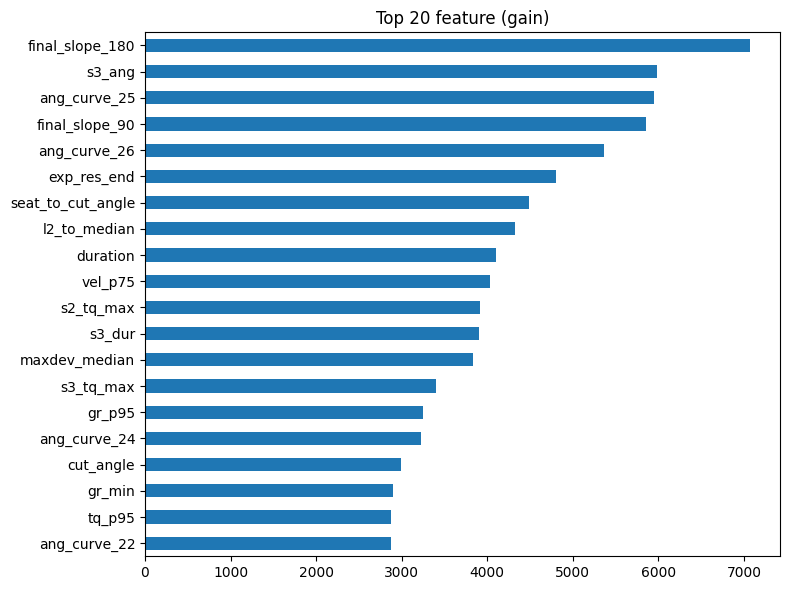

In [13]:
def metrics_of(p, y_true):
    pred = p.argmax(1)
    return {"acc": accuracy_score(y_true, pred), "f1_macro": f1_score(y_true, pred, average="macro")}

probs_va, probs_te, results = {}, {}, {}
y_tr, y_va, y_te = y[idx_tr], y[idx_va], y[idx_te]

# ---- LightGBM ----
t0 = time.time()
lgb_clf = lgb.LGBMClassifier(objective="multiclass" if N_CLASSES > 2 else "binary",
                             n_estimators=4000, learning_rate=0.03, num_leaves=31, min_child_samples=10,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0,
                             random_state=SEED, verbose=-1, n_jobs=N_JOBS)
lgb_clf.fit(F_all[idx_tr], y_tr, eval_set=[(F_all[idx_va], y_va)], callbacks=[lgb.early_stopping(200, verbose=False)])
probs_va["lgb"], probs_te["lgb"] = lgb_clf.predict_proba(F_all[idx_va]), lgb_clf.predict_proba(F_all[idx_te])
results["lgb"] = {"val": metrics_of(probs_va["lgb"], y_va), "test": metrics_of(probs_te["lgb"], y_te)}
print(f"LightGBM ({time.time() - t0:.0f}s, {lgb_clf.best_iteration_} vòng):", results["lgb"])

imp = pd.Series(lgb_clf.booster_.feature_importance("gain"), index=feat_cols).sort_values(ascending=False)
imp.head(20)[::-1].plot.barh(figsize=(8, 6), title="Top 20 feature (gain)"); plt.tight_layout(); plt.show()

In [14]:
# ---- MiniRocket + Ridge ----
from aeon.transformations.collection.convolution_based import MiniRocket
from scipy.special import softmax

ch_mean = X_time[idx_tr].mean(axis=(0, 2), keepdims=True)
ch_std = X_time[idx_tr].std(axis=(0, 2), keepdims=True) + 1e-6
def norm_x(X): return ((X - ch_mean) / ch_std).astype(np.float32)
Xn = norm_x(X_time)

def ridge_scores(model, Z):
    d = model.decision_function(Z)
    return np.c_[-d, d] if d.ndim == 1 else d

def fit_temperature(s_va, y_va):
    grid = np.logspace(-2, 2, 41)
    losses = [log_loss(y_va, softmax(s_va * T, 1), labels=np.arange(N_CLASSES)) for T in grid]
    return float(grid[int(np.argmin(losses))])

t0 = time.time()
mr = MiniRocket(n_kernels=MR_KERNELS, random_state=SEED, n_jobs=N_JOBS)
Z_tr = mr.fit_transform(Xn[idx_tr]); Z_va = mr.transform(Xn[idx_va]); Z_te = mr.transform(Xn[idx_te])
mr_scaler = StandardScaler().fit(Z_tr)
ridge = RidgeClassifierCV(alphas=np.logspace(-2, 5, 15)).fit(mr_scaler.transform(Z_tr), y_tr)
s_va, s_te = ridge_scores(ridge, mr_scaler.transform(Z_va)), ridge_scores(ridge, mr_scaler.transform(Z_te))
T_mr = fit_temperature(s_va, y_va)
probs_va["minirocket"], probs_te["minirocket"] = softmax(s_va * T_mr, 1), softmax(s_te * T_mr, 1)
results["minirocket"] = {"val": metrics_of(probs_va["minirocket"], y_va), "test": metrics_of(probs_te["minirocket"], y_te)}
print(f"MiniRocket ({time.time() - t0:.0f}s, alpha={ridge.alpha_:.3g}):", results["minirocket"])
del Z_tr, Z_va, Z_te; gc.collect()

MiniRocket (65s, alpha=3.16e+03): {'val': {'acc': 0.776685393258427, 'f1_macro': 0.6321734578994128}, 'test': {'acc': 0.788135593220339, 'f1_macro': 0.6172978208854427}}


101630

### 6b. Dữ liệu train "kiểu găng tay"

Găng tay đo thưa hơn (khoảng 100 Hz so với 833 Hz) và nhiễu hơn máy siết. Nếu CNN chỉ thấy dữ liệu sạch, accuracy sẽ tụt khi chuyển sang găng tay: ở lần chạy trước, mô hình đạt 84% trên dữ liệu sạch nhưng chỉ còn 69 - 77% trên tín hiệu mô phỏng găng tay. Vì vậy:
- Mỗi lần siết trong tập train được tạo thêm một bản giả lập găng tay, với tần số lấy mẫu ngẫu nhiên 50 - 200 Hz và mức nhiễu ngẫu nhiên 0.5 - 1.5 lần mức mặc định.
- Bộ lọc được tự chọn theo RMSE so với tín hiệu sạch, giữa ba lựa chọn: không lọc, Kalman nhân quả, và Kalman + RTS smoother (lọc cả xuôi lẫn ngược, dùng khi chấm điểm sau khi siết xong). Lần trước, Kalman nhân quả còn làm tín hiệu lực tệ hơn bản thô (RMSE 0.030 → 0.041 Nm) vì lực tăng rất dốc ở cuối.
- Khi train CNN, mỗi mẫu có xác suất `GLOVE_AUG_P` được thay bằng bản kiểu găng tay. Tập val và test vẫn giữ dữ liệu sạch để so sánh công bằng với các mô hình khác.

In [15]:
def kalman_cv(z, t, q=1.0, r=1.0, smooth=False):
    # Kalman mô hình vận tốc không đổi. smooth=False: nhân quả (chạy được realtime trên ESP32)
    # smooth=True: thêm RTS smoother (lọc ngược) - dùng khi đánh giá cả phiên sau khi siết xong
    n = len(z); xf = np.zeros((n, 2)); Pf = np.zeros((n, 2, 2)); xp = np.zeros((n, 2)); Pp = np.zeros((n, 2, 2))
    Fs = np.zeros((n, 2, 2)); x = np.array([z[0], 0.0]); P = np.eye(2) * 10.0
    for i in range(n):
        d = t[i] - t[i - 1] if i else 0.0
        Fm = np.array([[1.0, d], [0.0, 1.0]])
        Q = q * np.array([[d ** 4 / 4, d ** 3 / 2], [d ** 3 / 2, d ** 2]])
        x = Fm @ x; P = Fm @ P @ Fm.T + Q
        Fs[i], xp[i], Pp[i] = Fm, x, P
        S = P[0, 0] + r; K = P[:, 0] / S
        x = x + K * (z[i] - x[0]); P = P - np.outer(K, P[0, :])
        xf[i], Pf[i] = x, P
    if not smooth:
        return xf[:, 0]
    xs = xf.copy()
    for k in range(n - 2, -1, -1):
        Ck = Pf[k] @ Fs[k + 1].T @ np.linalg.pinv(Pp[k + 1])
        xs[k] = xf[k] + Ck @ (xs[k + 1] - xp[k + 1])
    return xs[:, 0]

def to_glove(c, fs=GLOVE_FS, tq_noise=GLOVE_TQ_NOISE, ang_noise=GLOVE_ANG_NOISE, rng=None):
    rng = rng or np.random.default_rng(0)
    tn = np.arange(0, c["t"][-1], 1 / fs)
    tq_clean, an_clean = np.interp(tn, c["t"], c["torque"]), np.interp(tn, c["t"], c["angle"])
    run = dict(time=tn, torque=tq_clean + rng.normal(0, tq_noise, len(tn)),
               angle=an_clean + rng.normal(0, ang_noise, len(tn)))
    return run, (tq_clean, an_clean)

def apply_filter(x, t, spec, r):
    mode, q = spec
    return x if mode == "none" else kalman_cv(x, t, q, r, smooth=(mode == "rts"))

# tự chọn bộ lọc cho từng kênh trên 30 lần siết mẫu của train
g_rng = np.random.default_rng(SEED)
calib = [to_glove(C[i], rng=g_rng) for i in expert_tr[:30]]
def choose_filter(key, cidx, r, qs):
    def rmse(spec):
        return np.mean([np.sqrt(np.mean((apply_filter(g[key], g["time"], spec, r) - cl[cidx]) ** 2)) for g, cl in calib])
    cands = [("none", 0.0)] + [(m, float(q_)) for m in ("kf", "rts") for q_ in qs]
    scores = {spec: rmse(spec) for spec in cands}
    best = min(scores, key=scores.get)
    best_kf = min((sp for sp in cands if sp[0] == "kf"), key=scores.get)
    return best, scores[("none", 0.0)], scores[best_kf], scores[best]
R_TQ, R_ANG = GLOVE_TQ_NOISE ** 2, GLOVE_ANG_NOISE ** 2
FILT_TQ, raw_tq, kf_tq, best_tq = choose_filter("torque", 0, R_TQ, np.logspace(-2, 8, 11))
FILT_ANG, raw_an, kf_an, best_an = choose_filter("angle", 1, R_ANG, np.logspace(2, 12, 11))
print(f"Lực: RMSE thô {raw_tq:.4f} | Kalman nhân quả {kf_tq:.4f} | chọn {FILT_TQ[0]} (q={FILT_TQ[1]:.3g}) → {best_tq:.4f} Nm")
print(f"Góc: RMSE thô {raw_an:.3f} | Kalman nhân quả {kf_an:.3f} | chọn {FILT_ANG[0]} (q={FILT_ANG[1]:.3g}) → {best_an:.3f} độ")

def glove_pipeline(runs, filt=True, desc="Găng tay"):
    out = []
    for r in runs:
        r = dict(r)
        if filt:
            r["torque"] = apply_filter(np.asarray(r["torque"], float), np.asarray(r["time"], float), FILT_TQ, R_TQ)
            r["angle"] = apply_filter(np.asarray(r["angle"], float), np.asarray(r["time"], float), FILT_ANG, R_ANG)
        r["gradient"] = None; r["step"] = np.zeros(len(r["time"]), int)
        out.append(r)
    return prepare(out, desc=desc)

# bản kiểu găng tay của tập train (tần số và mức nhiễu ngẫu nhiên)
t0 = time.time()
aug_rng = np.random.default_rng(SEED + 7)
aug_runs = [to_glove(C[i], fs=aug_rng.uniform(50, 200), tq_noise=GLOVE_TQ_NOISE * aug_rng.uniform(0.5, 1.5),
                     ang_noise=GLOVE_ANG_NOISE * aug_rng.uniform(0.5, 1.5), rng=aug_rng)[0] for i in idx_tr]
_, X_time_g_tr, _, X_abs_g_tr = glove_pipeline(aug_runs, filt=True, desc="Tạo dữ liệu kiểu găng tay")
del aug_runs; gc.collect()
print(f"Đã tạo {len(X_time_g_tr)} mẫu kiểu găng tay ({time.time() - t0:.0f}s)")

Lực: RMSE thô 0.0303 | Kalman nhân quả 0.0289 | chọn rts (q=1e+06) → 0.0255 Nm
Góc: RMSE thô 1.001 | Kalman nhân quả 0.948 | chọn rts (q=1e+09) → 0.716 độ


Tạo dữ liệu kiểu găng tay:   0%|          | 0/3545 [00:00<?, ?it/s]

Đã tạo 3545 mẫu kiểu găng tay (120s)


In [16]:
# ---- InceptionTime (CNN 1D) ----
class InceptionModule(nn.Module):
    def __init__(self, cin, nf=32, ks=(9, 19, 39), bottleneck=32):
        super().__init__()
        self.bott = nn.Conv1d(cin, bottleneck, 1, bias=False)
        self.convs = nn.ModuleList([nn.Conv1d(bottleneck, nf, k, padding=k // 2, bias=False) for k in ks])
        self.pool = nn.Sequential(nn.MaxPool1d(3, 1, 1), nn.Conv1d(cin, nf, 1, bias=False))
        self.bn = nn.BatchNorm1d(nf * (len(ks) + 1))
    def forward(self, x):
        z = self.bott(x)
        return F.relu(self.bn(torch.cat([c(z) for c in self.convs] + [self.pool(x)], 1)))

class InceptionTime(nn.Module):
    def __init__(self, cin, n_classes, nf=32, depth=6):
        super().__init__()
        self.mods = nn.ModuleList(); self.shortcuts = nn.ModuleList()
        c, res_c = cin, cin
        for d in range(depth):
            self.mods.append(InceptionModule(c, nf)); c = nf * 4
            if d % 3 == 2:
                self.shortcuts.append(nn.Sequential(nn.Conv1d(res_c, c, 1, bias=False), nn.BatchNorm1d(c))); res_c = c
        self.drop = nn.Dropout(0.2); self.fc = nn.Linear(c, n_classes)
    def forward(self, x):
        res = x; s = 0
        for d, m in enumerate(self.mods):
            x = m(x)
            if d % 3 == 2:
                x = F.relu(x + self.shortcuts[s](res)); res = x; s += 1
        return self.fc(self.drop(x.mean(-1)))

def augment(xb):
    xb = xb + 0.03 * torch.randn_like(xb)                                   # nhiễu cảm biến
    shift = int(torch.randint(-8, 9, (1,)))
    xb = torch.roll(xb, shift, dims=-1)                                     # lệch thời điểm bắt đầu
    if torch.rand(1) < 0.5:                                                 # che ngẫu nhiên 1 đoạn ngắn
        L_ = xb.shape[-1]; w = int(L_ * 0.05); s0 = int(torch.randint(0, L_ - w, (1,)))
        xb[..., s0:s0 + w] = 0
    return xb

@torch.no_grad()
def predict_cnn(model, X, bs=256):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE)
        out.append(F.softmax(model(xb).float(), 1).cpu().numpy())
    return np.concatenate(out)

def train_cnn(Xtr, ytr, Xva, yva, epochs, seed, bs=64, tag="", Xtr_alt=None):
    seed_all(seed)
    model = InceptionTime(Xtr.shape[1], N_CLASSES).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    steps = epochs * math.ceil(len(Xtr) / bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps, pct_start=0.25)
    crit = nn.CrossEntropyLoss(label_smoothing=0.05)
    use_amp = DEVICE == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    Xt_, yt_ = torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.int64))
    Xalt_ = torch.from_numpy(Xtr_alt) if Xtr_alt is not None else None
    best, best_state, hist = (-1, 1e9), None, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xt_))
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            xb = Xt_[b].clone()
            if Xalt_ is not None:                                   # thay một phần bằng bản kiểu găng tay
                m_ = torch.rand(len(b)) < GLOVE_AUG_P
                xb[m_] = Xalt_[b][m_]
            xb, yb = augment(xb).to(DEVICE), yt_[b].to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # tránh val acc sụp giữa chừng
            scaler.step(opt); scaler.update(); sched.step()
        pv = predict_cnn(model, Xva)
        acc, ll = accuracy_score(yva, pv.argmax(1)), log_loss(yva, pv, labels=np.arange(N_CLASSES))
        hist.append(acc)
        if (acc, -ll) > (best[0], -best[1]):
            best, best_state = (acc, ll), {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if (ep + 1) % 10 == 0 or ep == epochs - 1:
            print(f"  {tag} seed {seed} | epoch {ep + 1:3d} | val acc {acc:.4f} | best {best[0]:.4f}")
    model.load_state_dict(best_state)
    return model, hist

abs_mean = X_abs[idx_tr].mean(axis=(0, 2), keepdims=True)
abs_std = X_abs[idx_tr].std(axis=(0, 2), keepdims=True) + 1e-6
def norm_abs(X): return ((X - abs_mean) / abs_std).astype(np.float32)
Xb_n = norm_abs(X_abs)

def train_domain(name, Xd, Xalt_tr=None):
    t0 = time.time(); models, pv, pt = [], [], []
    for s in CNN_SEEDS:
        m, _ = train_cnn(Xd[idx_tr], y_tr, Xd[idx_va], y_va, CNN_EPOCHS, s, tag=name, Xtr_alt=Xalt_tr)
        models.append(m); pv.append(predict_cnn(m, Xd[idx_va])); pt.append(predict_cnn(m, Xd[idx_te]))
    probs_va[name], probs_te[name] = np.mean(pv, 0), np.mean(pt, 0)
    results[name] = {"val": metrics_of(probs_va[name], y_va), "test": metrics_of(probs_te[name], y_te)}
    print(f"InceptionTime {name} ({time.time() - t0:.0f}s):", results[name])
    return models

cnn_models = train_domain("cnn_time", Xn, norm_x(X_time_g_tr))           # miền thời gian
cnn_abs_models = train_domain("cnn_angle", Xb_n, norm_abs(X_abs_g_tr))   # miền góc tuyệt đối

  cnn_time seed 42 | epoch  10 | val acc 0.2542 | best 0.6826
  cnn_time seed 42 | epoch  20 | val acc 0.6798 | best 0.7022
  cnn_time seed 42 | epoch  30 | val acc 0.6545 | best 0.7584
  cnn_time seed 42 | epoch  40 | val acc 0.7669 | best 0.8076
  cnn_time seed 42 | epoch  50 | val acc 0.8160 | best 0.8343
  cnn_time seed 42 | epoch  60 | val acc 0.8287 | best 0.8343
  cnn_time seed 43 | epoch  10 | val acc 0.1503 | best 0.5927
  cnn_time seed 43 | epoch  20 | val acc 0.6994 | best 0.7051
  cnn_time seed 43 | epoch  30 | val acc 0.7079 | best 0.7654
  cnn_time seed 43 | epoch  40 | val acc 0.7795 | best 0.8104
  cnn_time seed 43 | epoch  50 | val acc 0.8343 | best 0.8343
  cnn_time seed 43 | epoch  60 | val acc 0.8343 | best 0.8343
InceptionTime cnn_time (204s): {'val': {'acc': 0.8314606741573034, 'f1_macro': 0.729923748832928}, 'test': {'acc': 0.8375706214689266, 'f1_macro': 0.7332135492821255}}
  cnn_angle seed 42 | epoch  10 | val acc 0.2219 | best 0.6124
  cnn_angle seed 42 | epo

Trọng số ensemble: {'lgb': 0.1, 'minirocket': 0.0, 'cnn_time': 0.9, 'cnn_angle': 0.0} | hệ số lớp chuẩn: 0.65
Trọng số cho mô hình chuỗi (găng tay): {'minirocket': 0.0, 'cnn_time': 0.6000000000000001, 'cnn_angle': 0.4}
            val_acc  test_acc  val_f1_macro  test_f1_macro
lgb          0.8034    0.8234        0.6858         0.6930
minirocket   0.7767    0.7881        0.6322         0.6173
cnn_time     0.8315    0.8376        0.7299         0.7332
cnn_angle    0.8160    0.8362        0.7085         0.7216
ensemble     0.8371    0.8418        0.7465         0.7455

                             precision    recall  f1-score   support

                 000_normal      0.833     0.950     0.888       382
        101_deformed-thread      1.000     0.091     0.167        11
        102_filed-screw-tip      0.714     0.625     0.667         8
        103_glued-screw-tip      0.889     0.667     0.762        12
           104_coated-screw      0.571     0.211     0.308        19
         10

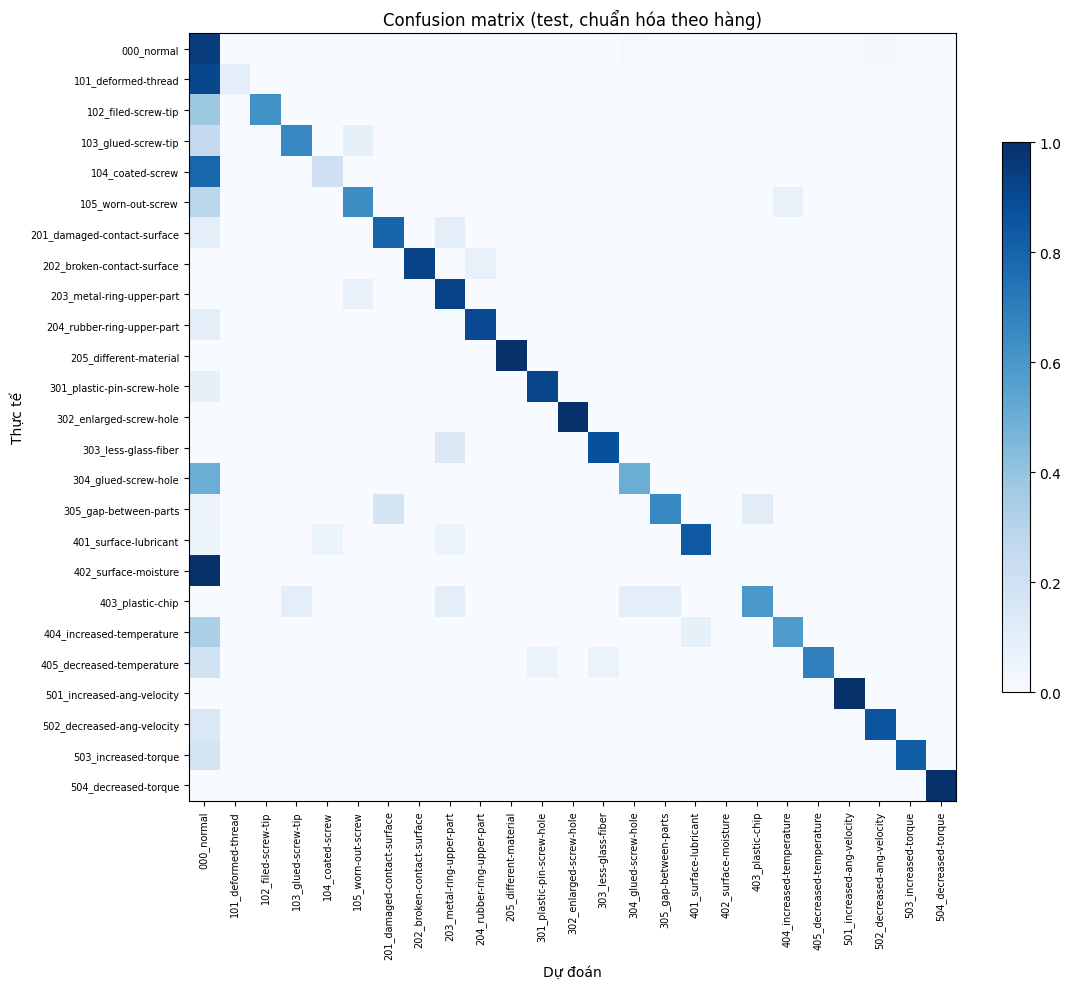

Accuracy đúng/sai (gộp lỗi) trên test: 0.8701


In [17]:
# ---- Ensemble: chọn trọng số trên val, báo cáo trên test ----
import itertools
names = list(probs_va)
grid = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(names)) if abs(sum(w) - 1) < 1e-6]
def blend(P, w): return sum(wi * P[n] for wi, n in zip(w, names))
def score(w):
    p = blend(probs_va, w)
    return (accuracy_score(y_va, p.argmax(1)), -log_loss(y_va, np.clip(p, 1e-9, 1), labels=np.arange(N_CLASSES)))
best_w = max(grid, key=score)
ens_weights = dict(zip(names, map(float, best_w)))
pva_e, pte_e = blend(probs_va, best_w), blend(probs_te, best_w)
# hệ số cho lớp 000_normal, chọn trên val
normal_col = int(np.where(le.classes_ == ("000_normal" if TASK == "multiclass" else "OK"))[0][0])
def with_bias(p, b):
    q_ = p.copy(); q_[:, normal_col] *= b; return q_ / q_.sum(1, keepdims=True)
b_grid = np.round(np.arange(0.5, 2.01, 0.05), 2)
normal_bias = float(max(b_grid, key=lambda b: (accuracy_score(y_va, with_bias(pva_e, b).argmax(1)), -abs(b - 1))))
probs_va["ensemble"], probs_te["ensemble"] = with_bias(pva_e, normal_bias), with_bias(pte_e, normal_bias)
results["ensemble"] = {"val": metrics_of(probs_va["ensemble"], y_va), "test": metrics_of(probs_te["ensemble"], y_te)}
print("Trọng số ensemble:", ens_weights, "| hệ số lớp chuẩn:", normal_bias)

# trọng số riêng cho 3 mô hình chuỗi thời gian (chỉ cần lực + góc) - dùng cho dữ liệu găng tay ở mục 8
TS_MODELS = ["minirocket", "cnn_time", "cnn_angle"]
ts_grid = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=3) if abs(sum(w) - 1) < 1e-6]
ts_best = max(ts_grid, key=lambda w: accuracy_score(y_va, with_bias(sum(wi * probs_va[k] for wi, k in zip(w, TS_MODELS)), normal_bias).argmax(1)))
ts_weights = dict(zip(TS_MODELS, map(float, ts_best)))
print("Trọng số cho mô hình chuỗi (găng tay):", ts_weights)

table = pd.DataFrame({k: {"val_acc": v["val"]["acc"], "test_acc": v["test"]["acc"],
                          "val_f1_macro": v["val"]["f1_macro"], "test_f1_macro": v["test"]["f1_macro"]}
                      for k, v in results.items()}).T
print(table.round(4).to_string())

pred_te = probs_te["ensemble"].argmax(1)
print("\n" + classification_report(y_te, pred_te, labels=np.arange(N_CLASSES), target_names=le.classes_, digits=3, zero_division=0))
cm = confusion_matrix(y_te, pred_te, labels=np.arange(N_CLASSES), normalize="true")
plt.figure(figsize=(max(6, N_CLASSES * 0.45), max(5, N_CLASSES * 0.4)))
plt.imshow(cm, cmap="Blues", vmin=0, vmax=1); plt.colorbar(fraction=0.03)
plt.xticks(range(N_CLASSES), le.classes_, rotation=90, fontsize=7); plt.yticks(range(N_CLASSES), le.classes_, fontsize=7)
plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title("Confusion matrix (test, chuẩn hóa theo hàng)")
plt.tight_layout(); plt.show()

# ngoài ra: độ chính xác đúng/sai khi gộp mọi loại lỗi lại
if TASK == "multiclass":
    normal_id = int(np.where(le.classes_ == "000_normal")[0][0])
    acc_bin = accuracy_score(y_te != normal_id, pred_te != normal_id)
    results["ensemble"]["test"]["acc_ok_vs_nok"] = acc_bin
    print(f"Accuracy đúng/sai (gộp lỗi) trên test: {acc_bin:.4f}")

## 7. Mô phỏng robot siết theo mô hình điểm ngắt

Phát lại từng lần siết trong tập test như thể robot đang siết theo thời gian thực. Ở mỗi thời điểm robot hỏi mô hình 5b "còn bao nhiêu độ?", và dừng ngay khi câu trả lời ≤ `STOP_TOL`. So với luật dừng cố định của máy siết thông thường: dừng khi lực đạt ngưỡng (98% lực đỉnh trung vị của các lần chuẩn).

Đây là mô phỏng chính sách dừng trên dữ liệu thật đã ghi, chưa phải mô phỏng động lực học của tay robot.

Mô phỏng:   0%|          | 0/708 [00:00<?, ?it/s]

                                       thao tác mẫu (normal+OK)  thao tác lỗi
số lần siết                                             365.000       326.000
MAE góc dừng - mô hình (độ)                               2.958       145.322
MAE góc dừng - luật lực (độ)                              6.670       147.950
trung vị sai số góc - mô hình (độ)                        3.000         3.750
trung vị sai số góc - luật lực (độ)                       6.750         7.500
% dừng trong ±10 độ - mô hình                            99.726        75.153
% dừng trong ±10 độ - luật lực                           94.521        68.405
Sai lệch lực khi dừng - mô hình (Nm)                      0.014         0.284
Sai lệch lực khi dừng - luật lực (Nm)                     0.027         0.270


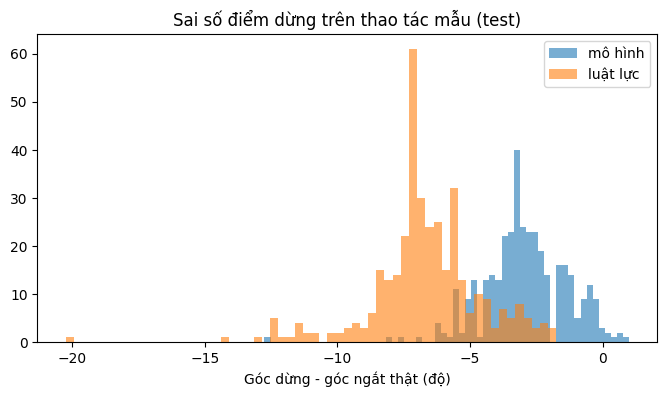

In [18]:
thr_rule = 0.98 * np.median([C[i]["torque_s"][C[i]["cut"]] for i in expert_tr])

def simulate(i):
    c = C[i]; k = c["cut"]; P = point_table(c, idx=np.arange(len(c["t"])))
    pred = cut_model.predict(P[CUT_FEATS])
    j_m = int(np.argmax(pred <= STOP_TOL)) if (pred <= STOP_TOL).any() else len(pred) - 1
    hit = c["torque_s"] >= thr_rule
    j_r = int(np.argmax(hit)) if hit.any() else len(pred) - 1
    return {"run": i, "faulty": is_faulty[i], "expert": is_expert[i],
            "model_err_deg": c["angle"][j_m] - c["angle"][k], "rule_err_deg": c["angle"][j_r] - c["angle"][k],
            "model_torque_at_stop": c["torque_s"][j_m], "rule_torque_at_stop": c["torque_s"][j_r],
            "true_peak_torque": c["torque_s"][k]}

sim = pd.DataFrame([simulate(i) for i in tqdm(idx_te, desc="Mô phỏng")])
def summarize(df):
    return pd.Series({
        "số lần siết": len(df),
        "MAE góc dừng - mô hình (độ)": df["model_err_deg"].abs().mean(),
        "MAE góc dừng - luật lực (độ)": df["rule_err_deg"].abs().mean(),
        "trung vị sai số góc - mô hình (độ)": df["model_err_deg"].abs().median(),
        "trung vị sai số góc - luật lực (độ)": df["rule_err_deg"].abs().median(),
        "% dừng trong ±10 độ - mô hình": (df["model_err_deg"].abs() <= 10).mean() * 100,
        "% dừng trong ±10 độ - luật lực": (df["rule_err_deg"].abs() <= 10).mean() * 100,
        "Sai lệch lực khi dừng - mô hình (Nm)": (df["model_torque_at_stop"] - df["true_peak_torque"]).abs().mean(),
        "Sai lệch lực khi dừng - luật lực (Nm)": (df["rule_torque_at_stop"] - df["true_peak_torque"]).abs().mean(),
    })
sim_table = pd.DataFrame({"thao tác mẫu (normal+OK)": summarize(sim[sim.expert == 1]),
                          "thao tác lỗi": summarize(sim[sim.faulty == 1])})
print(sim_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sim.loc[sim.expert == 1, "model_err_deg"].clip(-100, 100), bins=60, alpha=0.6, label="mô hình")
ax.hist(sim.loc[sim.expert == 1, "rule_err_deg"].clip(-100, 100), bins=60, alpha=0.6, label="luật lực")
ax.set(xlabel="Góc dừng - góc ngắt thật (độ)", title="Sai số điểm dừng trên thao tác mẫu (test)"); ax.legend(); plt.show()

## 8. Dữ liệu găng tay của nhóm: so sánh & kiểm tra độ bền

**8a. Mô phỏng tín hiệu găng tay** (luôn chạy): lấy chính tập test, hạ tần số lấy mẫu xuống `GLOVE_FS`, cộng nhiễu loadcell và nhiễu IMU, bỏ gradient và thông tin bước của máy siết. Sau đó chạy lại mô hình, không lọc và có lọc (bộ lọc đã chọn ở 6b). Kết quả cho biết mô hình còn dùng được bao nhiêu khi chuyển sang găng tay - số liệu này nên đưa vào báo cáo.

**8b. Dữ liệu thật của nhóm** (chạy khi có file): xuất từ Job 2 ra CSV với các cột
`session_id, time_s, torque_nm, angle_deg` và tùy chọn `label` (`000_normal` hoặc tên lỗi). Đặt đường dẫn vào `TEAM_CSV`.

In [19]:
def eval_timeseries_models(Xt_new, Xb_new, y_true):
    Xn_new = norm_x(Xt_new)
    P = {"cnn_time": np.mean([predict_cnn(m, Xn_new) for m in cnn_models], 0),
         "cnn_angle": np.mean([predict_cnn(m, norm_abs(Xb_new)) for m in cnn_abs_models], 0),
         "minirocket": softmax(ridge_scores(ridge, mr_scaler.transform(mr.transform(Xn_new))) * T_mr, 1)}
    w = np.array([ts_weights[k] for k in TS_MODELS])
    p_ens = with_bias(sum(wi * P[k] for wi, k in zip(w, TS_MODELS)), normal_bias)
    out = {k: accuracy_score(y_true, P[k].argmax(1)) for k in TS_MODELS}
    out["ensemble_chuoi"] = accuracy_score(y_true, p_ens.argmax(1))
    return out, p_ens

glove_runs = [to_glove(C[i], rng=np.random.default_rng(SEED + 100 + int(i)))[0] for i in idx_te]
rows = {"dữ liệu sạch (máy siết)": eval_timeseries_models(X_time[idx_te], X_abs[idx_te], y_te)[0]}
filt_name = f"lọc {FILT_TQ[0]}/{FILT_ANG[0]}"
for use_f in (False, True):
    key = f"găng tay {GLOVE_FS} Hz " + (f"+ {filt_name}" if use_f else "(không lọc)")
    Cg, Xtg, Xag, Xbg = glove_pipeline(glove_runs, filt=use_f)
    rows[key] = eval_timeseries_models(Xtg, Xbg, y_te)[0]
    dg = cdist_dtw(Xag[:, :, None], std_curve[None, :, None], global_constraint="sakoe_chiba",
                   sakoe_chiba_radius=R_DTW, n_jobs=-1).ravel()
    rows[key]["AUC_DTW_dung_sai"] = roc_auc_score(is_faulty[idx_te], dg)
rows["dữ liệu sạch (máy siết)"]["AUC_DTW_dung_sai"] = roc_auc_score(is_faulty[idx_te], D_dtw[idx_te])
robust_table = pd.DataFrame(rows).T
print(robust_table.round(4).to_string())
print("\nNhận xét: nếu accuracy găng tay tụt nhiều so với dữ liệu sạch → cần fine-tune bằng dữ liệu nhóm tự thu (cell dưới).")

Găng tay:   0%|          | 0/708 [00:00<?, ?it/s]

Găng tay:   0%|          | 0/708 [00:00<?, ?it/s]

                               minirocket  cnn_time  cnn_angle  ensemble_chuoi  AUC_DTW_dung_sai
dữ liệu sạch (máy siết)            0.7881    0.8376     0.8362          0.8503            0.6141
găng tay 100 Hz (không lọc)        0.6059    0.8249     0.8107          0.8263            0.6121
găng tay 100 Hz + lọc rts/rts      0.5395    0.8234     0.8249          0.8305            0.6135

Nhận xét: nếu accuracy găng tay tụt nhiều so với dữ liệu sạch → cần fine-tune bằng dữ liệu nhóm tự thu (cell dưới).


In [20]:
# ---- 8b. Dữ liệu thật của nhóm ----
TEAM_CSV = os.environ.get("TEAM_CSV", "")   # vd "/content/glove_sessions.csv" (export từ API Job 2)
TEAM_TORQUE_SCALE = 1.0    # quy đổi nếu lực mục tiêu của nhóm khác 1.4 Nm, vd 1.4 / luc_muc_tieu_nhom
FINE_TUNE_EPOCHS = 15

if TEAM_CSV and os.path.exists(TEAM_CSV):
    df = pd.read_csv(TEAM_CSV).sort_values(["session_id", "time_s"])
    team_runs, team_ids, team_labels = [], [], []
    for sid, g in df.groupby("session_id"):
        if len(g) < 10: continue
        team_runs.append(dict(time=g["time_s"].values, torque=g["torque_nm"].values * TEAM_TORQUE_SCALE,
                              angle=g["angle_deg"].values))
        team_ids.append(sid); team_labels.append(g["label"].iloc[0] if "label" in g else None)
    Ct, Xtt, Xat, Xbt = glove_pipeline(team_runs, filt=True)
    dt_team = cdist_dtw(Xat[:, :, None], std_curve[None, :, None], global_constraint="sakoe_chiba",
                        sakoe_chiba_radius=R_DTW, n_jobs=-1).ravel()
    _, p_team = eval_timeseries_models(Xtt, Xbt, np.zeros(len(Xtt), int))
    report = pd.DataFrame({"session_id": team_ids, "label": team_labels,
                           "du_doan": le.classes_[p_team.argmax(1)], "do_tin_cay": p_team.max(1),
                           "dtw_toi_duong_chuan": dt_team,
                           "nam_ngoai_dai_chuan_%": ((Xat < band_lo) | (Xat > band_hi)).mean(1) * 100,
                           "luc_dinh_Nm": [c["torque_s"][c["cut"]] for c in Ct],
                           "goc_ngat_do": [c["angle"][c["cut"]] for c in Ct]})
    print(report.round(3).to_string())

    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    axes[0].fill_between(ANG_GRID, band_lo, band_hi, alpha=0.2, label="dải chuẩn PyScrew")
    axes[0].plot(ANG_GRID, std_curve, "k", lw=2, label="đường chuẩn PyScrew")
    for xa in Xat[:20]: axes[0].plot(ANG_GRID, xa, alpha=0.5, lw=1)
    axes[0].set(title="Dữ liệu găng tay so với đường chuẩn", xlabel="Góc so với điểm ngắt (độ)", ylabel="Lực (Nm)"); axes[0].legend()
    axes[1].hist(D_dtw[is_faulty == 0], bins=50, density=True, alpha=0.5, label="PyScrew chuẩn")
    axes[1].hist(D_dtw[is_faulty == 1], bins=50, density=True, alpha=0.5, label="PyScrew lỗi")
    axes[1].hist(dt_team, bins=20, density=True, alpha=0.7, label="găng tay nhóm")
    axes[1].set(title="Phân bố khoảng cách DTW", xlabel="DTW"); axes[1].legend(); plt.tight_layout(); plt.show()

    # Fine-tune CNN nếu nhóm có nhãn và nhãn nằm trong các lớp đã học
    has_lab = [l is not None and l in set(le.classes_) for l in team_labels]
    if sum(has_lab) >= 10:
        ids = np.where(has_lab)[0]; yt = le.transform(np.array(team_labels, dtype=object)[ids])
        strat = yt if np.bincount(yt).min() >= 2 else None
        tr_i, va_i = train_test_split(ids, test_size=0.3, random_state=SEED, stratify=strat)
        Xn_t = norm_x(Xtt); y_map = dict(zip(ids, yt))
        ft = InceptionTime(Xn_t.shape[1], N_CLASSES).to(DEVICE); ft.load_state_dict(cnn_models[0].state_dict())
        opt = torch.optim.AdamW(ft.parameters(), lr=2e-4, weight_decay=1e-2); crit = nn.CrossEntropyLoss(label_smoothing=0.05)
        ytr_t = np.array([y_map[i] for i in tr_i]); yva_t = np.array([y_map[i] for i in va_i])
        print("Trước fine-tune: acc val găng tay =", accuracy_score(yva_t, predict_cnn(ft, Xn_t[va_i]).argmax(1)))
        for ep in range(FINE_TUNE_EPOCHS):
            ft.train()
            for b in np.array_split(np.random.permutation(len(tr_i)), max(1, len(tr_i) // 16)):
                xb = augment(torch.from_numpy(Xn_t[tr_i[b]]).clone()).to(DEVICE)
                yb = torch.from_numpy(ytr_t[b].astype(np.int64)).to(DEVICE)
                opt.zero_grad(); crit(ft(xb), yb).backward(); opt.step()
        print("Sau fine-tune:  acc val găng tay =", accuracy_score(yva_t, predict_cnn(ft, Xn_t[va_i]).argmax(1)))
        torch.save(ft.state_dict(), os.path.join(OUT_DIR, "cnn_finetuned_glove.pt"))
else:
    print("Chưa có TEAM_CSV - bỏ qua 8b. Khi Job 1/Job 2 có dữ liệu, điền đường dẫn rồi chạy lại cell này.")

Chưa có TEAM_CSV - bỏ qua 8b. Khi Job 1/Job 2 có dữ liệu, điền đường dẫn rồi chạy lại cell này.


## 9. Lưu mô hình & hàm dự đoán

Toàn bộ mô hình, đường chuẩn, tham số chuẩn hóa và số liệu kết quả được lưu vào `artifacts_job3/` và nén thành `artifacts_job3.zip` để tải về hoặc đưa cho Job 2 tích hợp vào backend.

`predict_session(time_s, torque_nm, angle_deg)` nhận 1 phiên thao tác thô (từ găng tay hoặc máy siết) và trả về: loại thao tác dự đoán, độ tin cậy, khoảng cách tới đường chuẩn, % điểm nằm ngoài dải chuẩn, lực đỉnh và góc ngắt.

In [21]:
import joblib

def predict_session(time_s, torque_nm, angle_deg, glove=True):
    run = dict(time=np.asarray(time_s, float), torque=np.asarray(torque_nm, float), angle=np.asarray(angle_deg, float))
    (c,), Xt1, Xa1, Xb1 = glove_pipeline([run], filt=glove)
    _, p = eval_timeseries_models(Xt1, Xb1, np.zeros(1, int))
    d = cdist_dtw(Xa1[:, :, None], std_curve[None, :, None], global_constraint="sakoe_chiba",
                  sakoe_chiba_radius=R_DTW).ravel()[0]
    top = np.argsort(p[0])[::-1][:3]
    return {"du_doan": le.classes_[top[0]], "do_tin_cay": float(p[0, top[0]]),
            "top3": {le.classes_[i]: round(float(p[0, i]), 4) for i in top},
            "dtw_toi_duong_chuan": float(d),
            "nam_ngoai_dai_chuan_%": float(((Xa1[0] < band_lo) | (Xa1[0] > band_hi)).mean() * 100),
            "luc_dinh_Nm": float(c["torque_s"][c["cut"]]), "goc_ngat_do": float(c["angle"][c["cut"]])}

# thử trên 1 lần siết của tập test, giả lập như dữ liệu găng tay
demo = to_glove(C[idx_te[0]], rng=np.random.default_rng(1))[0]
print("Nhãn thật:", le.classes_[y[idx_te[0]]])
print(json.dumps(predict_session(demo["time"], demo["torque"], demo["angle"]), ensure_ascii=False, indent=2))

joblib.dump({"model": lgb_clf, "feature_cols": feat_cols}, os.path.join(OUT_DIR, "lgb_classifier.joblib"))
joblib.dump({"minirocket": mr, "scaler": mr_scaler, "ridge": ridge, "temperature": T_mr}, os.path.join(OUT_DIR, "minirocket_ridge.joblib"))
for k, m in enumerate(cnn_models):
    torch.save(m.state_dict(), os.path.join(OUT_DIR, f"inceptiontime_time_seed{k}.pt"))
for k, m in enumerate(cnn_abs_models):
    torch.save(m.state_dict(), os.path.join(OUT_DIR, f"inceptiontime_angle_seed{k}.pt"))
joblib.dump({"torque_quantiles": expert, "cutoff_model": cut_model, "expert_feats": EXPERT_FEATS, "cut_feats": CUT_FEATS},
            os.path.join(OUT_DIR, "expert_models.joblib"))
np.savez(os.path.join(OUT_DIR, "standard_curve.npz"), angle_grid=ANG_GRID, std_curve=std_curve,
         band_lo=band_lo, band_med=band_med, band_hi=band_hi)
summary = {
    "dataset": f"PyScrew {SCENARIO}" + (" (SMOKE_TEST - dữ liệu giả lập)" if SMOKE_TEST else ""),
    "n_runs": int(len(y)), "task": TASK, "classes": le.classes_.tolist(),
    "split": {"train": int(len(idx_tr)), "val": int(len(idx_va)), "test": int(len(idx_te))},
    "classification": {k: {s: {m: float(v) for m, v in d.items()} for s, d in r.items()} for k, r in results.items()},
    "ensemble_weights": ens_weights, "normal_class_bias": normal_bias, "timeseries_weights_glove": ts_weights,
    "split_method": "StratifiedGroupKFold theo workpiece_id", "control_group_merged_into_normal": True,
    "expert_torque_model": expert_metrics, "cutoff_model": cut_metrics,
    "robot_simulation": sim_table.round(4).to_dict(),
    "glove_robustness": robust_table.round(4).to_dict(),
    "preprocess": {"L_TIME": L_TIME, "L_ANG": L_ANG, "ANGLE_WINDOW": ANGLE_WINDOW,
                   "channel_mean": ch_mean.ravel().tolist(), "channel_std": ch_std.ravel().tolist(),
                   "ABS_ANGLE_MAX": ABS_ANGLE_MAX, "L_ABS": L_ABS,
                   "abs_mean": abs_mean.ravel().tolist(), "abs_std": abs_std.ravel().tolist(),
                   "filter_torque": list(FILT_TQ), "filter_angle": list(FILT_ANG),
                   "glove_sim": {"fs": GLOVE_FS, "tq_noise": GLOVE_TQ_NOISE, "ang_noise": GLOVE_ANG_NOISE, "aug_p": GLOVE_AUG_P}},
}
with open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
zip_path = shutil.make_archive(OUT_DIR, "zip", OUT_DIR)
print("Đã lưu:", zip_path)
print(table.round(4).to_string())

Nhãn thật: 000_normal


Găng tay:   0%|          | 0/1 [00:00<?, ?it/s]

{
  "du_doan": "000_normal",
  "do_tin_cay": 0.7859055568153688,
  "top3": {
    "000_normal": 0.7859,
    "402_surface-moisture": 0.0563,
    "101_deformed-thread": 0.0367
  },
  "dtw_toi_duong_chuan": 0.8039154897247669,
  "nam_ngoai_dai_chuan_%": 4.6875,
  "luc_dinh_Nm": 1.4088798246678116,
  "goc_ngat_do": 1815.0606591695923
}
Đã lưu: /content/artifacts_job3.zip
            val_acc  test_acc  val_f1_macro  test_f1_macro
lgb          0.8034    0.8234        0.6858         0.6930
minirocket   0.7767    0.7881        0.6322         0.6173
cnn_time     0.8315    0.8376        0.7299         0.7332
cnn_angle    0.8160    0.8362        0.7085         0.7216
ensemble     0.8371    0.8418        0.7465         0.7455
